In [1]:
import pandas as pd
import numpy as np
import os, re
import ast

In [2]:
sorted(os.listdir('logs'))[-4:]

['2026-10-29_22-32-35_FBcontinual-walker-run',
 '2026-10-29_22-32-35_FBcontinual-walker-run_1',
 '2026-10-29_22-32-36_FBcontinual-walker-run',
 '2026-10-29_22-32-36_FBcontinual-walker-run_1']

In [3]:
folders = sorted(os.listdir('logs'))[-4:]

DATE = re.compile(r'^\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2}_')
LAST = 3

In [29]:
# last-LAST average of each run, grouped by the args in the first line of info.txt (seed excluded)
groups = {}
for f in folders:
    with open(f'logs/{f}/info.txt') as fh:
        args = ast.literal_eval(fh.readline().strip())
    args.pop('seed', None)
    key = tuple(sorted((k, str(v)) for k, v in args.items()))

    df = pd.read_csv(f'logs/{f}/eval_log.csv')
    cols = [c for c in df.columns if c.endswith('_mean') or c.endswith('_eps') or c.endswith('_corr')] + ['mean_fresh_all'] + ['mean_tracked_tasks']
    # cols = df.columns
    # cols = [c for c in df.columns if c.endswith('_mean')]
    groups.setdefault(key, []).append(df.tail(LAST)[cols].mean())

# args that differ between groups become the row label; the shared ones are printed once
all_keys = sorted({k for key in groups for k, _ in key})
varying = [k for k in all_keys if len({dict(key).get(k) for key in groups}) > 1]
common = {k: dict(next(iter(groups)))[k] for k in all_keys if k not in varying}
print('common args:', common, '\n')

# one table: "mean ± std" across the seeds of each group
rows = {}
for key, runs in groups.items():
    label = ', '.join(f'{k}={dict(key).get(k)}' for k in varying) or 'all'
    runs = pd.DataFrame(runs)
    m, s = runs.mean(), runs.std()
    rows[label] = {'n_runs': len(runs)} | {c: f'{m[c]:.2f} ± {s[c]:.1f}' for c in runs.columns}

table = pd.DataFrame(rows).T.sort_index()
print(table.to_string())
table.to_csv('eval_summary.csv')

common args: {'checkpoint': 'models/2026-10-29_14-44-51_FBpretrain-walker/fb_agent_latest.pickle', 'env_name': 'walker', 'eval_each_steps': '10', 'freeze_fb': '1', 'lam': '0', 'mu_b': '0', 'mu_q': '0', 'num_evals': '20', 'steps_per_stage': '300000', 'tasks': 'run'} 

                                         n_runs stand_fresh_mean stand_fresh_rew_corr stand_fresh_eps walk_fresh_mean walk_fresh_rew_corr walk_fresh_eps vel8_fresh_mean vel8_fresh_rew_corr vel8_fresh_eps run_fresh_mean run_fresh_rew_corr run_fresh_eps flip_fresh_mean flip_fresh_rew_corr flip_fresh_eps run_tracked_mean run_tracked_rew_corr run_tracked_eps mean_fresh_all mean_tracked_tasks
actor_z_task_frac=0, z_task_spread=None       1     785.01 ± nan           0.62 ± nan      0.30 ± nan    805.44 ± nan          0.65 ± nan     0.38 ± nan    371.03 ± nan          0.62 ± nan     0.35 ± nan   315.70 ± nan         0.61 ± nan    0.35 ± nan    434.56 ± nan          0.67 ± nan     0.33 ± nan     292.66 ± nan           0.60 ± nan 

In [31]:
table[['run_fresh_mean', 'mean_fresh_all']].sort_values('run_fresh_mean')

,run_fresh_mean,mean_fresh_all
"actor_z_task_frac=1.0, z_task_spread=0.2",315.45 ± nan,516.57 ± nan
"actor_z_task_frac=0, z_task_spread=None",315.70 ± nan,542.35 ± nan
"actor_z_task_frac=0.5, z_task_spread=0.5",340.34 ± nan,498.53 ± nan
"actor_z_task_frac=0.8, z_task_spread=0.5",345.31 ± nan,484.67 ± nan


In [35]:
table[['run_fresh_eps', 'run_fresh_rew_corr']]

,run_fresh_eps,run_fresh_rew_corr
"actor_z_task_frac=0, z_task_spread=None",0.35 ± nan,0.61 ± nan
"actor_z_task_frac=0.5, z_task_spread=0.5",0.35 ± nan,0.61 ± nan
"actor_z_task_frac=0.8, z_task_spread=0.5",0.35 ± nan,0.61 ± nan
"actor_z_task_frac=1.0, z_task_spread=0.2",0.35 ± nan,0.61 ± nan


In [33]:
0.623108983039856 + 0.6167051196098328 + 0.5903770923614502
0.623108983039856 + 0.6167051196098328 + 0.5903770923614502

1.830191195011139

---

# Random:

In [3]:
import ast, glob, os, re
import numpy as np
import pandas as pd

In [4]:
LAST_K = 3               # number of last evals averaged (mid + end rows of the last stage)
LAST_TRAIN_ROWS = 10     # number of last training chunks averaged for r_b, r_q, l_rec, z_shrink

In [5]:
LOG_FOLDERS = sorted(glob.glob('logs/*FBcontinual-walker-*'))   # or an explicit list of folders
print(len(LOG_FOLDERS), 'folders')

47 folders


In [6]:
def _lit(v):
    v = v.strip()
    try:
        return ast.literal_eval(v)
    except Exception:
        return v

def parse_info(folder):
    path = os.path.join(folder, 'info.txt')
    text = open(path).read() if os.path.exists(path) else ''
    lines = text.splitlines()
    info = {}
    try:
        info.update(ast.literal_eval(lines[0]))                      # kwargs dict
    except Exception:
        pass
    m = re.search(r'FBConfig\((.*)\)', text)                         # full config (overrides kwargs)
    if m:
        for k, v in re.findall(r"(\w+)=('[^']*'|[^,]+)", m.group(1)):
            info[k] = _lit(v)
    for key in ['steps_per_stage', 'n_labeled', 'n_big']:
        m = re.search(rf'{key}=(\d+)', text)
        if m:
            info[key] = int(m.group(1))
    m = re.search(r"tasks=(\[[^\]]*\])", text)
    if m:
        info['tasks'] = ast.literal_eval(m.group(1))
    else:
        info['tasks'] = str(info.get('tasks', '')).strip('[]').replace("'", '').split(',')
    return info

In [26]:
def summarize(folder):
    info = parse_info(folder)
    if info.get('target_agg') != 'min' or info.get('lr') != 1e-4:      # old-config runs
        return None, None
    ev_path, tr_path = f'{folder}/eval_log.csv', f'{folder}/training_log.csv'
    if not (os.path.exists(ev_path) and os.path.exists(tr_path)):
        return None, None
    ev, tr = pd.read_csv(ev_path), pd.read_csv(tr_path)
    if len(ev) == 0 or len(tr) == 0 or 'stage' not in ev.columns or ev.stage.isna().all():
        print('skipped (no eval or training rows yet):', os.path.basename(folder))
        return None, None
    labels = [c[:-len('_fresh_mean')] for c in ev.columns if c.endswith('_fresh_mean')]
    stream = info['tasks']
    others = [l for l in labels if l not in stream]
    base = ev[ev.tag == 'baseline']
    stage = int(ev.stage.max())
    late = ev[(ev.stage == stage) & ev.tag.isin(['mid', 'end'])].tail(LAST_K)
    if len(late) == 0:
        print('skipped (only the baseline eval so far):', os.path.basename(folder))
        return None, None

    def agg(rows, labs, what):
        if len(rows) == 0 or len(labs) == 0:
            return np.nan
        return float(np.mean([rows[f'{l}_fresh_{what}'].mean() for l in labs]))

    row = dict(run=os.path.basename(folder), tasks='+'.join(stream), seed=info.get('seed', 0),
               lam=info.get('lam'), mu_b=info.get('mu_b'), mu_q=info.get('mu_q'),
               cross_fit=info.get('cross_fit'), ridge=info.get('ridge'), n_est=info.get('n_est'),
               n_labeled=info.get('n_labeled'), lr=info.get('lr'), steps=info.get('steps_per_stage'),
               n_evals=len(late), finished=bool((late.tag == 'end').any()))

    # t = tasks of the stream (learned), o = the other env tasks, all = every task. _b = baseline, d_ = change
    for name, labs in [('t', stream), ('o', others), ('all', labels)]:
        for what, key in [('mean', 'ret'), ('eps', 'eps'), ('rew_corr', 'corr')]:
            now, before = agg(late, labs, what), agg(base, labs, what)
            row[f'{key}_{name}'], row[f'{key}_{name}_b'], row[f'd_{key}_{name}'] = now, before, now - before

    end = ev[(ev.stage == stage) & (ev.tag == 'end')]               # tracked latent z_j (end of stage only)
    row['trk_ret'] = float(np.mean([end[f'{l}_tracked_mean'].iloc[-1] for l in stream])) if len(end) else np.nan
    row['trk_eps'] = float(np.mean([end[f'{l}_tracked_eps'].iloc[-1] for l in stream])) if len(end) else np.nan

    last = tr[tr.stage == stage].tail(LAST_TRAIN_ROWS)
    for c in ['r_b', 'r_q', 'l_rec', 'z_shrink']:
        row[c] = float(last[c].mean())

    per = pd.DataFrame({l: dict(ret=late[f'{l}_fresh_mean'].mean(),
                                ret_b=base[f'{l}_fresh_mean'].mean() if len(base) else np.nan,
                                eps=late[f'{l}_fresh_eps'].mean(),
                                eps_b=base[f'{l}_fresh_eps'].mean() if len(base) else np.nan) for l in labels}).T
    return row, per

rows, per_task = [], {}
for f in LOG_FOLDERS:
    r, p = summarize(f)
    if r is not None:
        rows.append(r)
        per_task[r['run']] = p
df = pd.DataFrame(rows)

# comparison with the pure-FB control (lam = mu_b = mu_q = 0) of the same tasks / steps
# is_ctrl = (df.lam == 0) & (df.mu_b == 0) & (df.mu_q == 0)
is_ctrl = (df.lam == 0) & (df.mu_b == 0) & (df.mu_q == 0) & (df.n_evals >= LAST_K) & df.finished & (df.steps == 50000)
ctrl = df[is_ctrl].groupby(['tasks', 'steps'])[['ret_t', 'ret_o', 'ret_all', 'eps_t', 'eps_o', 'r_b', 'r_q']].mean()
keys = list(zip(df.tasks, df.steps))
for c in ctrl.columns:
    df[f'{c}_vs_ctrl'] = df[c].values - np.array([ctrl[c].get(k, np.nan) for k in keys])
df = df.set_index('run')
print(len(df), 'runs;', int(is_ctrl.sum()), 'control run(s)')

skipped (only the baseline eval so far): 2026-10-28_23-51-31_FBcontinual-walker-run
35 runs; 1 control run(s)


In [27]:
SORT_BY, ASCENDING = ['ret_t_vs_ctrl'], [False]       # <- change here, e.g. ['ret_t_vs_ctrl'], [False]

show_cols = ['tasks', 'lam', 'mu_b', 'mu_q', 'cross_fit', 'ridge', 'n_labeled', 'steps', 'n_evals', 'finished',
            #  'eps_t', 'd_eps_t', 'eps_o', 'd_eps_o', 'corr_t',
             'ret_t', 'ret_t_vs_ctrl', 'ret_o', 'ret_o_vs_ctrl', 'ret_all_vs_ctrl',
            #  'trk_ret', 'r_b', 'r_q', 'l_rec', 'z_shrink'
             ]
res = df.sort_values(SORT_BY, ascending=ASCENDING)[show_cols]
res.style.format(precision=3, na_rep='-') \
   .background_gradient(subset=['ret_t_vs_ctrl', 'ret_o_vs_ctrl'], cmap='RdYlGn')
   # .background_gradient(subset=['d_eps_t', 'd_eps_o'], cmap='RdYlGn_r') \

,tasks,lam,mu_b,mu_q,cross_fit,ridge,n_labeled,steps,n_evals,finished,ret_t,ret_t_vs_ctrl,ret_o,ret_o_vs_ctrl,ret_all_vs_ctrl
run,,,,,,,,,,,,,,,
2026-10-29_01-09-24_FBcontinual-walker-run,run,10.000,1.000,0.010,False,0.000,10000,50000,1,True,350.959,24.387,682.082,72.211,62.646
2026-10-29_13-16-20_FBcontinual-walker-run,run,10.000,0.000,0.010,False,0.000,10000,50000,3,True,348.779,22.207,694.563,84.691,72.194
2026-10-29_13-00-07_FBcontinual-walker-run,run,10.000,1.000,0.010,False,0.000,3000,50000,3,True,347.386,20.815,679.069,69.197,59.521
2026-10-29_12-52-21_FBcontinual-walker-run,run,10.000,10.000,0.000,False,0.000,10000,50000,3,True,346.224,19.652,701.095,91.224,76.910
2026-10-29_13-39-39_FBcontinual-walker-run,run,10.000,1.000,0.010,False,0.000,10000,50000,3,True,345.190,18.618,671.841,61.970,53.299
2026-10-29_12-52-21_FBcontinual-walker-run_1,run,10.000,1.000,0.010,False,0.000,10000,50000,3,True,344.840,18.268,677.829,67.957,58.020
2026-10-29_13-08-20_FBcontinual-walker-run,run,10.000,0.000,0.001,False,0.000,10000,50000,3,True,343.717,17.145,686.246,76.375,64.529
2026-10-29_12-52-20_FBcontinual-walker-run,run,10.000,1.000,0.010,True,0.000,3000,50000,3,True,343.518,16.947,672.812,62.941,53.742
2026-10-29_13-24-18_FBcontinual-walker-run,run,10.000,0.000,0.100,False,0.000,10000,50000,3,True,342.498,15.926,656.903,47.032,40.811


In [20]:
def per_task_table(what='ret', delta=True):
    tab = {run: (p[what] - p[what + '_b']) if delta else p[what] for run, p in per_task.items()}
    return pd.DataFrame(tab).T

display(per_task_table('ret').loc[res.index].round(1))     # return change per task vs baseline
# display(per_task_table('eps').loc[res.index].round(3))     # eps change per task vs baseline

,stand,walk,vel8,run,flip
run,,,,,
2026-10-29_13-56-30_FBcontinual-walker-run,-81.6,-16.4,-125.3,-114.9,-124.9
2026-10-29_13-40-24_FBcontinual-walker-run,-77.1,5.1,-128.5,-136.6,-126.9
2026-10-29_13-16-32_FBcontinual-walker-run,-155.4,-26.3,-91.9,-121.1,-268.4
2026-10-29_13-08-32_FBcontinual-walker-run,31.3,5.7,-92.1,-80.4,-67.9
2026-10-29_13-56-32_FBcontinual-walker-run,-7.2,-55.2,-41.6,-28.4,-71.4
2026-10-29_13-48-28_FBcontinual-walker-run,70.6,-40.4,17.2,-18.2,-1.8
2026-10-29_13-00-26_FBcontinual-walker-run,86.1,-36.1,-34.8,-35.3,-12.0
2026-10-29_13-32-26_FBcontinual-walker-run,109.7,-1.4,-21.8,-15.5,-2.0
2026-10-29_13-32-17_FBcontinual-walker-run,-92.1,-70.7,-32.1,-18.6,1.6


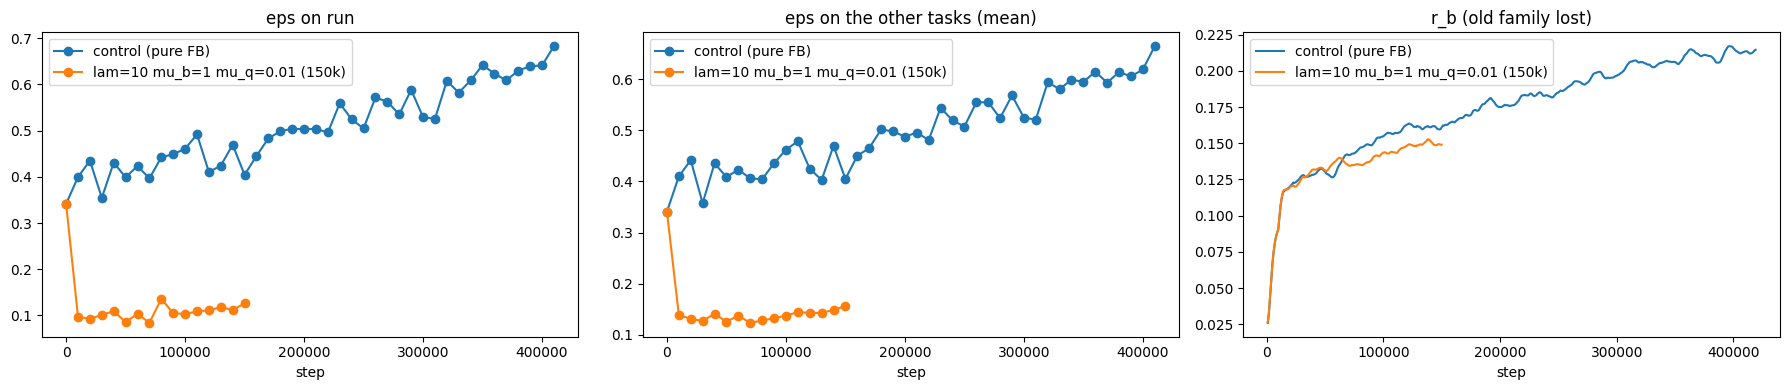

In [28]:
import matplotlib.pyplot as plt
RUNS = {
    'control (pure FB)':               'logs/2026-10-29_13-56-11_FBcontinual-walker-run',
    'lam=10 mu_b=1 mu_q=0.01 (150k)':  'logs/2026-10-29_13-48-46_FBcontinual-walker-run',
}
others = ['stand', 'walk', 'vel8', 'flip']
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for name, f in RUNS.items():
    ev, tr = pd.read_csv(f'{f}/eval_log.csv'), pd.read_csv(f'{f}/training_log.csv')
    axs[0].plot(ev.step, ev['run_fresh_eps'], marker='o', label=name)
    axs[1].plot(ev.step, ev[[f'{t}_fresh_eps' for t in others]].mean(axis=1), marker='o', label=name)
    axs[2].plot(tr.step, tr.r_b.rolling(10, min_periods=1).mean(), label=name)
for a, t in zip(axs, ['eps on run', 'eps on the other tasks (mean)', 'r_b (old family lost)']):
    a.set_title(t); a.set_xlabel('step'); a.legend()
plt.tight_layout()